   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.7/108.7 kB 2.3 MB/s eta 0:00:00
  Attempting uninstall: yfinance
    Found existing installation: yfinance 0.2.52
    Uninstalling yfinance-0.2.52:
      Successfully uninstalled yfinance-0.2.52


[*********************100%***********************]  1 of 1 completed


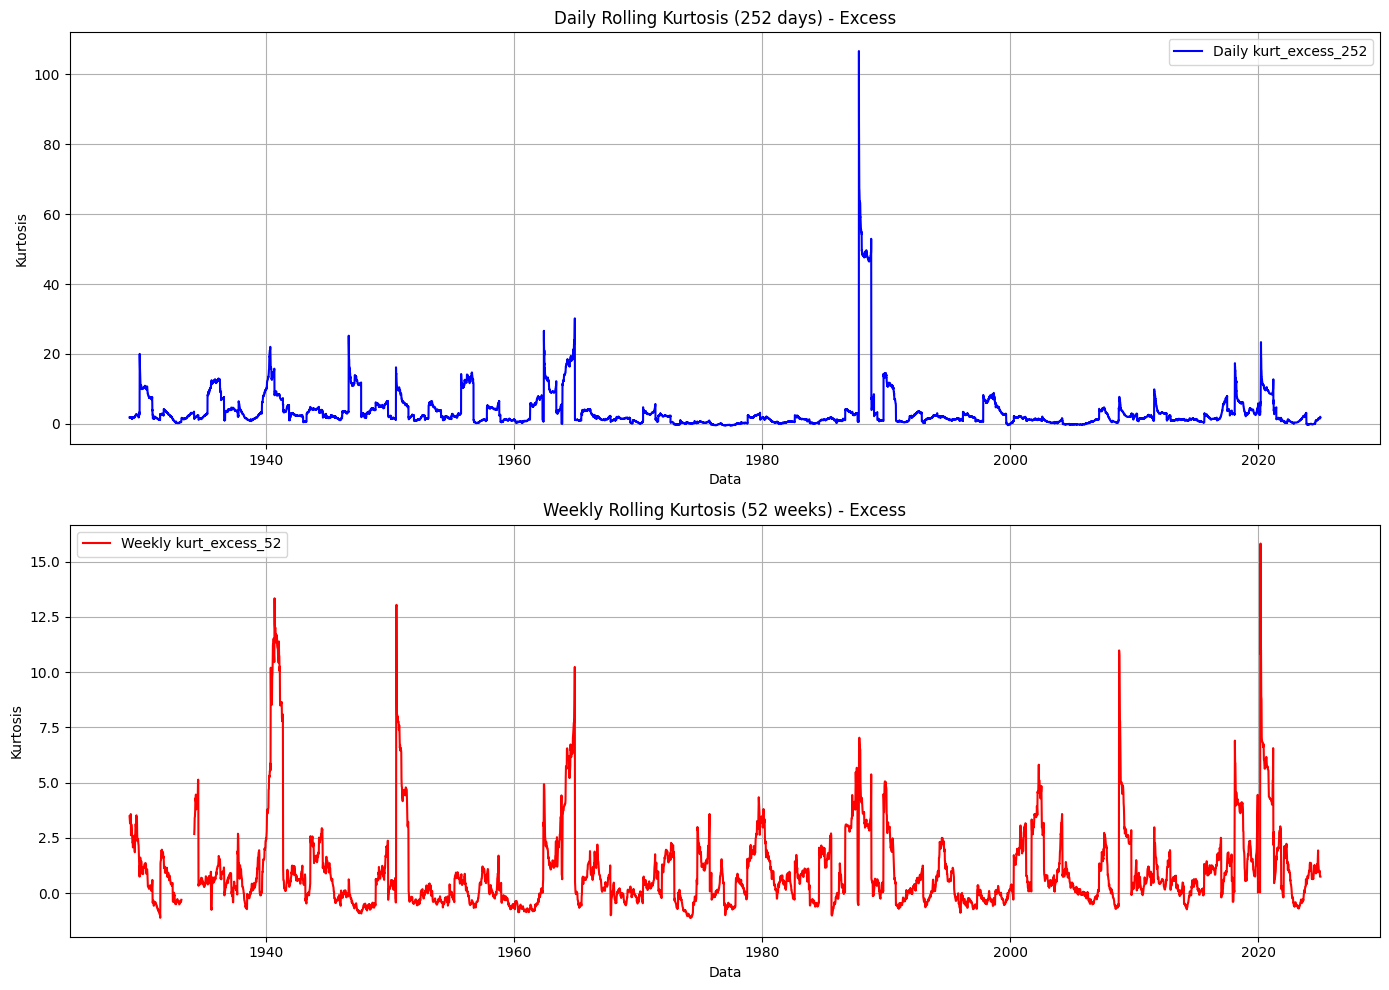

In [1]:
!pip install yfinance pandas numpy matplotlib
!pip install --upgrade yfinance

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

########################################
# PARAMETRI
########################################
TICKER = '^GSPC'            # S&P 500
START_DATE = '1927-01-01'
END_DATE   = '2025-01-01'
ROLLING_DAYS = 252         # Per la kurtosis giornaliera (1 anno di trading approx)
ROLLING_WEEKS = 52         # Per la kurtosis settimanale (1 anno di weeks approx)

########################################
# 1. SCARICA DATI MULTIINDEX
########################################
df_raw = yf.download(
    TICKER,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=False
)

########################################
# 2. ESTRARRE '^GSPC' e RENDERE COLONNE MONOLIVELLO
########################################
df_simplified = df_raw.xs(TICKER, level='Ticker', axis=1)

########################################
# 3. SCEGLI COLONNA PREZZO
########################################
col_to_use = 'Adj Close' if 'Adj Close' in df_simplified.columns else 'Close'
df_daily = df_simplified[[col_to_use]].rename(columns={col_to_use: 'Price'}).copy()

########################################
# 4. CALCOLO RENDIMENTI LOG GIORNALIERI E KURTOSIS
########################################
df_daily['log_return'] = np.log(df_daily['Price'] / df_daily['Price'].shift(1))
df_daily['kurt_excess_252'] = df_daily['log_return'].rolling(ROLLING_DAYS).kurt()
df_daily['kurt_raw_252'] = df_daily['kurt_excess_252'] + 3

########################################
# 5. RESAMPLE SETTIMANALE E KURTOSIS
########################################
df_weekly = df_daily.resample('W').last().copy()
df_weekly['log_return'] = np.log(df_weekly['Price'] / df_weekly['Price'].shift(1))
df_weekly['kurt_excess_52'] = df_weekly['log_return'].rolling(ROLLING_WEEKS).kurt()
df_weekly['kurt_raw_52'] = df_weekly['kurt_excess_52'] + 3

########################################
# 6. Plot dei due subplot
########################################
plt.figure(figsize=(14, 10))

# Subplot 1: Daily kurtosis 252 (excess)
plt.subplot(2, 1, 1)
plt.plot(df_daily.index, df_daily['kurt_excess_252'], color='blue', label='Daily kurt_excess_252')
plt.title('Daily Rolling Kurtosis (252 days) - Excess')
plt.xlabel('Data')
plt.ylabel('Kurtosis')
plt.grid(True)
plt.legend()

# Subplot 2: Weekly kurtosis 52 (excess)
plt.subplot(2, 1, 2)
plt.plot(df_weekly.index, df_weekly['kurt_excess_52'], color='red', label='Weekly kurt_excess_52')
plt.title('Weekly Rolling Kurtosis (52 weeks) - Excess')
plt.xlabel('Data')
plt.ylabel('Kurtosis')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()